Write a md file in dcos folder.

plots in plots folders.

likewise scripts in scripts folder.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r'C:\Users\Admin\OneDrive\Desktop\Coursework\semester 6\AML Business\Project\AMLB\brazil_ecommerce\datasets\processed\olist_merged_clean.csv')

In [3]:
df.head()

,order_id,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,is_late,n_items,total_price,total_freight,...,payment_type,customer_lat,customer_lng,seller_lat,seller_lng,distance_km,actual_delivery_days,estimated_delivery_days,delivery_delay_days,same_state
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 11:59:59,0,1,29.99,8.72,...,voucher,-23.576983,-46.587161,-23.680729,-46.444238,18.576110,8.436574,16.044051,-7.607477,1
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 11:59:59,0,1,118.70,22.76,...,boleto,-12.177924,-44.660711,-19.807681,-43.980427,851.495069,13.782037,19.637755,-5.855718,0
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 11:59:59,0,1,159.90,19.22,...,credit_card,-16.745150,-48.514783,-21.363502,-48.229601,514.410666,9.394213,27.139699,-17.745486,0
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 11:59:59,0,1,45.00,27.20,...,credit_card,-5.774190,-35.271143,-19.837682,-43.924053,1822.226336,13.208750,26.688808,-13.480058,0
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 11:59:59,0,1,19.90,8.72,...,credit_card,-23.676370,-46.514627,-23.543395,-46.262086,29.676625,2.873877,12.612037,-9.738160,1


In [16]:
df.shape

(96189, 34)

In [5]:
df.columns

Index(['order_id', 'order_purchase_timestamp', 'order_approved_at',
       'order_delivered_carrier_date', 'order_delivered_customer_date',
       'order_estimated_delivery_date', 'is_late', 'n_items', 'total_price',
       'total_freight', 'max_weight_g', 'max_length_cm', 'max_height_cm',
       'max_width_cm', 'product_photos_qty', 'primary_category',
       'customer_zip_code_prefix', 'customer_city', 'customer_state',
       'seller_zip_code_prefix', 'seller_city', 'seller_state',
       'payment_value', 'payment_installments', 'payment_type', 'customer_lat',
       'customer_lng', 'seller_lat', 'seller_lng', 'distance_km',
       'actual_delivery_days', 'estimated_delivery_days',
       'delivery_delay_days', 'same_state'],
      dtype='object')

In [6]:
unique_sellers = df['seller_zip_code_prefix'].nunique()
unique_buyers = df['customer_zip_code_prefix'].nunique()

print(f"Total unique sellers: {unique_sellers}")
print(f"Total unique buyers: {unique_buyers}")

Total unique sellers: 2149
Total unique buyers: 14886


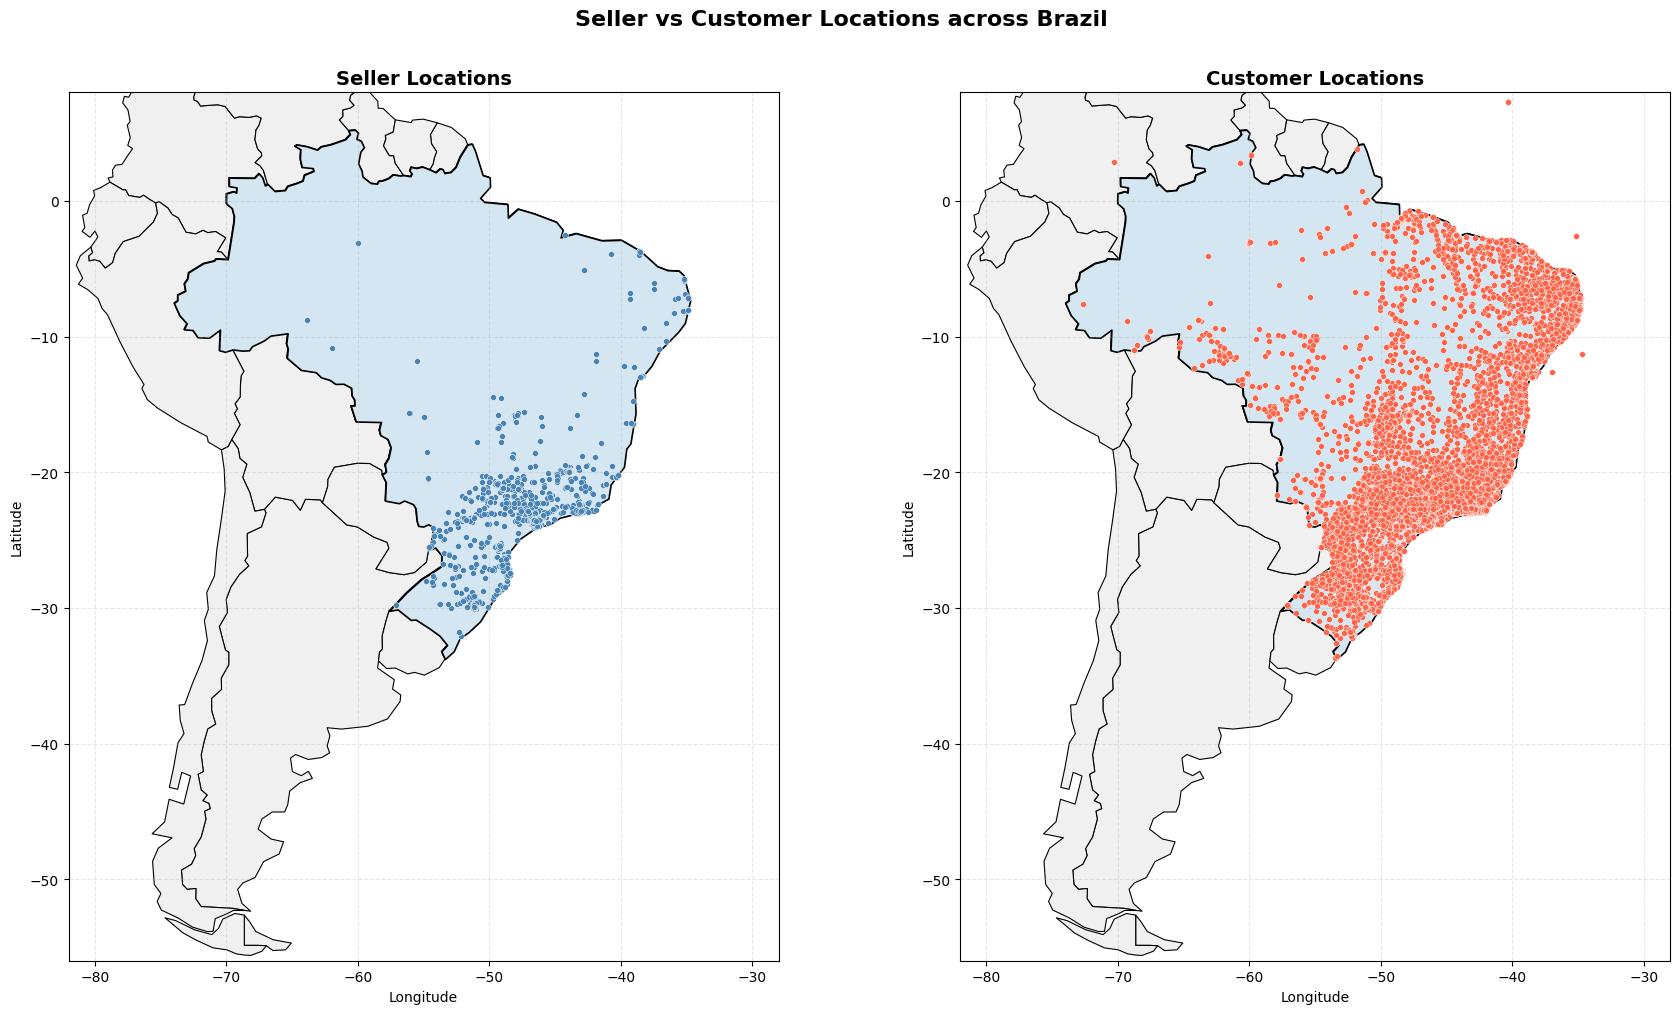

In [7]:
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns

# --- Load South America ---
world = gpd.read_file(
    "https://raw.githubusercontent.com/johan/world.geo.json/master/countries.geo.json"
)

south_america = world[world['name'].isin([
    'Brazil', 'Argentina', 'Chile', 'Peru', 'Colombia', 'Venezuela',
    'Bolivia', 'Ecuador', 'Paraguay', 'Uruguay', 'Guyana',
    'Suriname', 'French Guiana'
])]

brazil = south_america[south_america['name'] == 'Brazil']

# --- Data ---
seller_locations = df[['seller_lat', 'seller_lng']].dropna().drop_duplicates()
customer_locations = df[['customer_lat', 'customer_lng']].dropna().drop_duplicates()

# seller_locations = df[['seller_lat', 'seller_lng']].dropna()
# customer_locations = df[['customer_lat', 'customer_lng']].dropna()
# --- Plot ---
fig, axes = plt.subplots(1, 2, figsize=(18, 10))

configs = [
    (seller_locations,  'seller_lng',   'seller_lat',   'steelblue', 'Seller Locations'),
    (customer_locations,'customer_lng',  'customer_lat', 'tomato',    'Customer Locations'),
]

for ax, (data, lng_col, lat_col, color, title) in zip(axes, configs):

    # South America base
    south_america.plot(ax=ax, color='#f0f0f0', edgecolor='black', linewidth=0.8)

    # Brazil highlight
    brazil.plot(ax=ax, color='#d4e6f1', edgecolor='black', linewidth=1.2)

    # Scatter
    sns.scatterplot(
        data=data,
        x=lng_col,
        y=lat_col,
        s=18,
        alpha=1,
        color=color,
        ax=ax
    )

    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    ax.set_xlim(-82, -28)
    ax.set_ylim(-56, 8)
    ax.grid(True, linestyle='--', alpha=0.3)

plt.suptitle('Seller vs Customer Locations across Brazil', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### uniqure seller and buyers per state

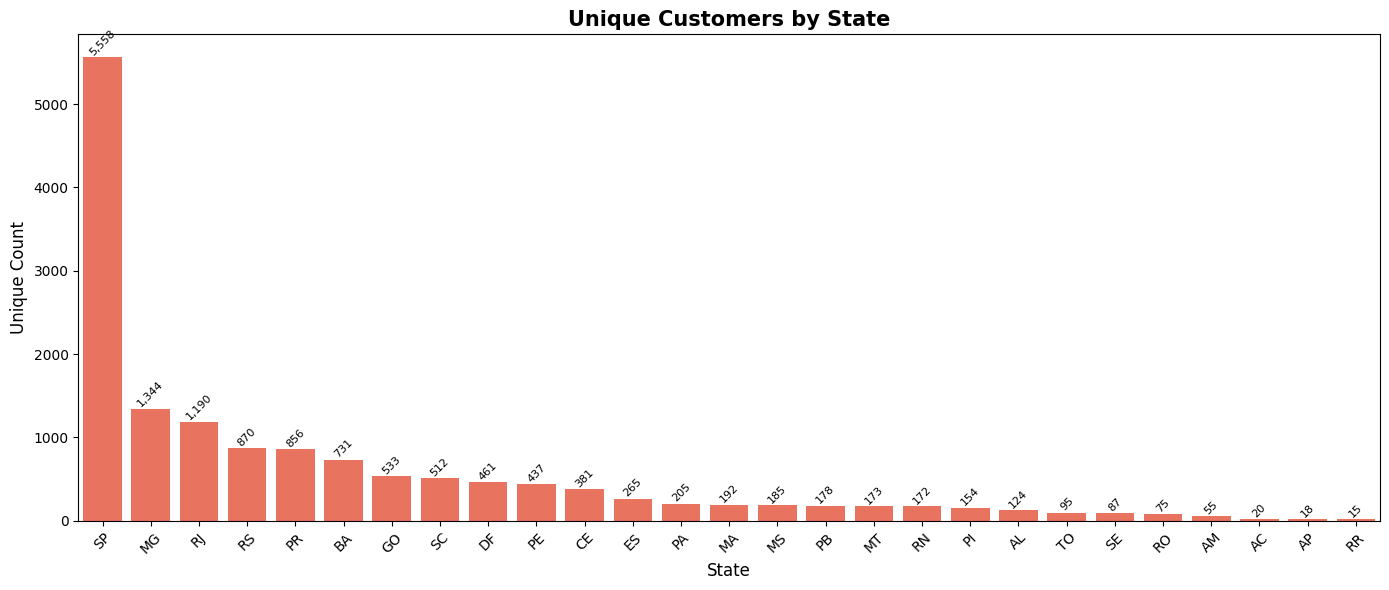

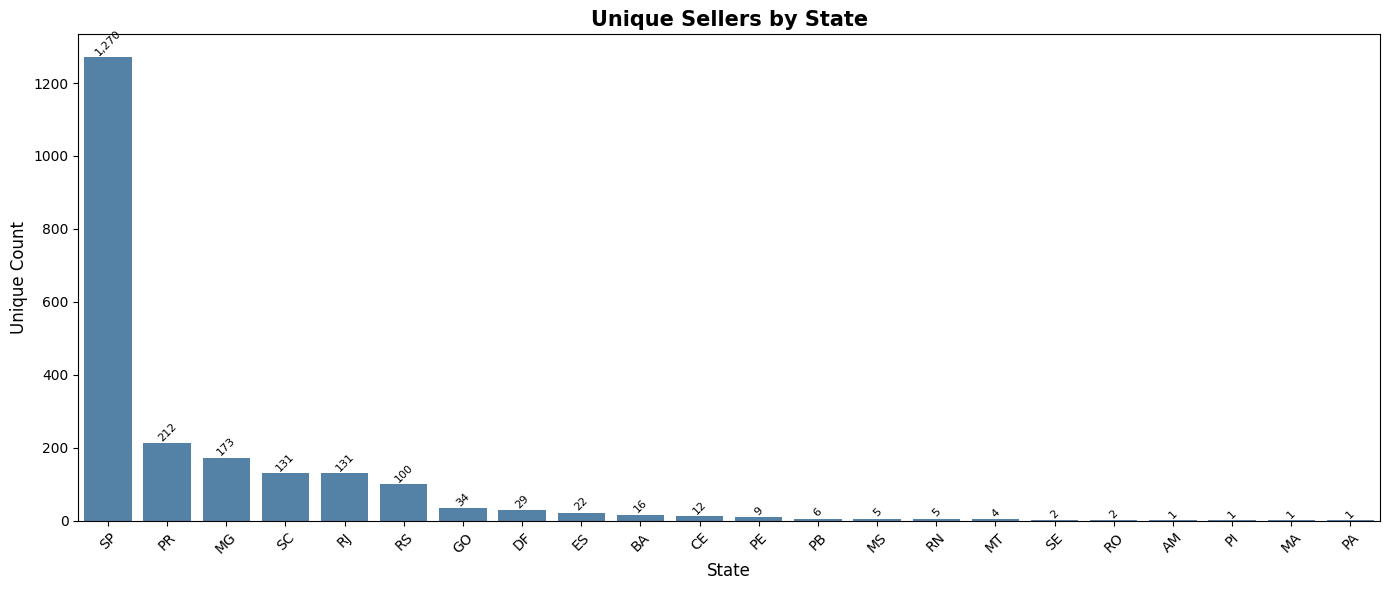

In [8]:
configs = [
    ('customer_state', 'customer_zip_code_prefix', 'tomato',    'Unique Customers by State'),
    ('seller_state',   'seller_zip_code_prefix',   'steelblue', 'Unique Sellers by State'),
]

for col, id_col, color, title in configs:
    fig, ax = plt.subplots(figsize=(14, 6))

    # Count unique zip codes per state as proxy for unique customers/sellers
    state_counts = df.groupby(col)[id_col].nunique().sort_values(ascending=False)

    sns.barplot(
        x=state_counts.index,
        y=state_counts.values,
        color=color,
        ax=ax
    )

    ax.set_title(title, fontsize=15, fontweight='bold')
    ax.set_xlabel('State', fontsize=12)
    ax.set_ylabel('Unique Count', fontsize=12)
    ax.tick_params(axis='x', rotation=45)

    for p in ax.patches:
        ax.annotate(
            f'{int(p.get_height()):,}',
            (p.get_x() + p.get_width() / 2., p.get_height()),
            ha='center', va='bottom', fontsize=8, rotation=45
        )

    plt.tight_layout()
    plt.show()

### Total Orders and Products by Customer State

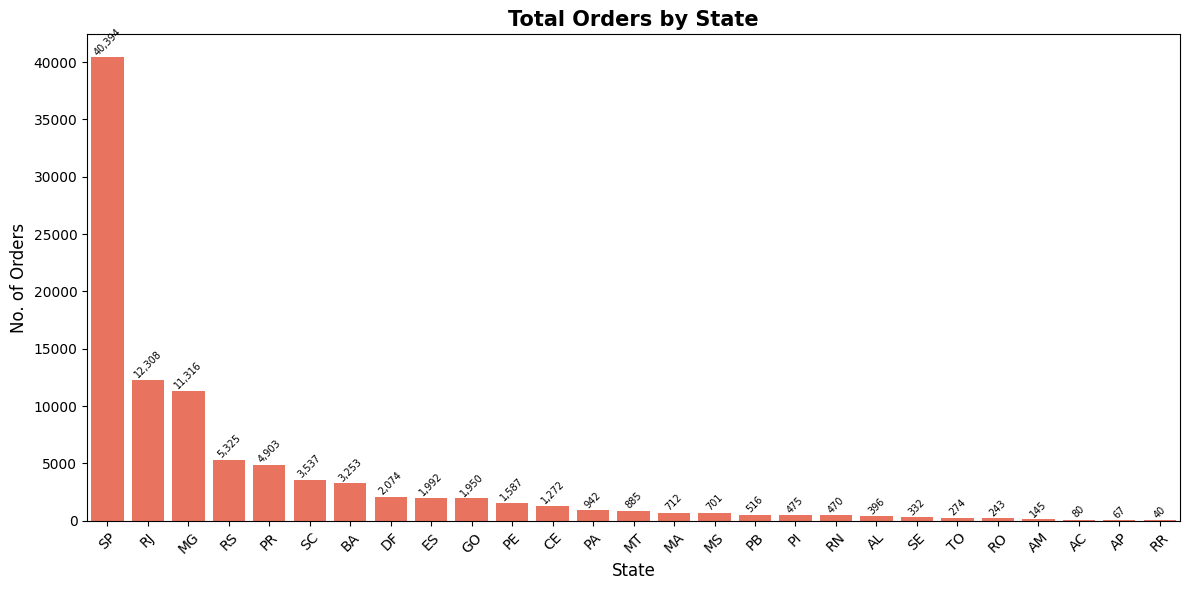

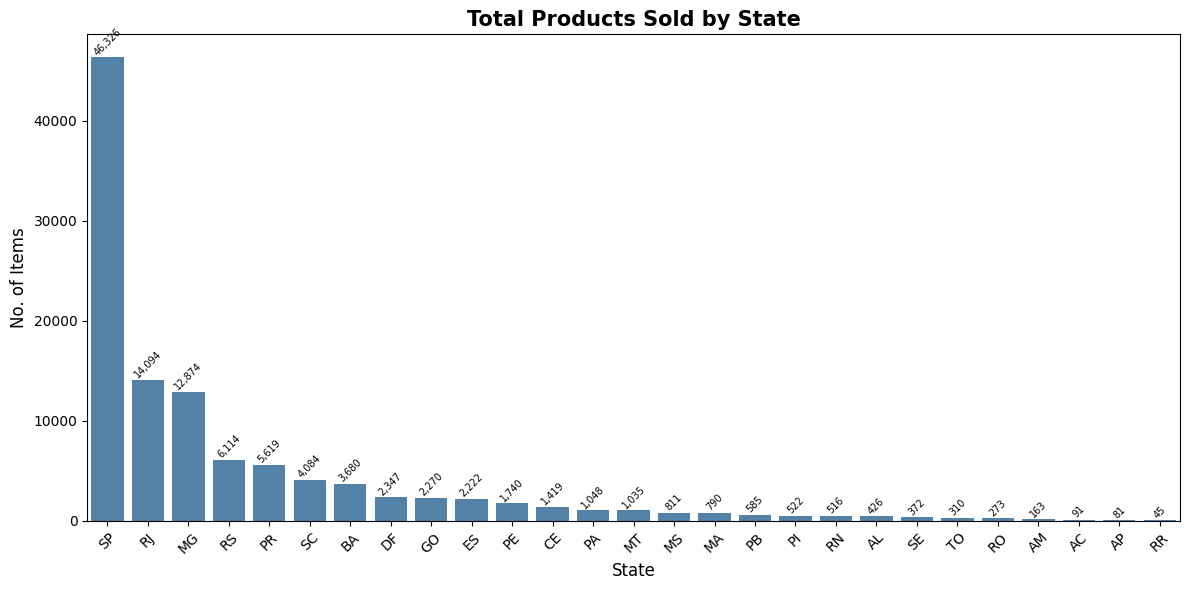

In [9]:
# Total Orders by Customer State
order_counts = df['customer_state'].value_counts().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(x=order_counts.index, y=order_counts.values, color='tomato', ax=ax)

ax.set_title('Total Orders by State', fontsize=15, fontweight='bold')
ax.set_xlabel('State', fontsize=12)
ax.set_ylabel('No. of Orders', fontsize=12)
ax.tick_params(axis='x', rotation=45)

for p in ax.patches:
    ax.annotate(
        f'{int(p.get_height()):,}',
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='bottom', fontsize=7, rotation=45
    )

plt.tight_layout()
plt.show()


#Plot for Total Products Sold by Customer State
product_counts = df.groupby('customer_state')['n_items'].sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(x=product_counts.index, y=product_counts.values, color='steelblue', ax=ax)

ax.set_title('Total Products Sold by State', fontsize=15, fontweight='bold')
ax.set_xlabel('State', fontsize=12)
ax.set_ylabel('No. of Items', fontsize=12)
ax.tick_params(axis='x', rotation=45)

for p in ax.patches:
    ax.annotate(
        f'{int(p.get_height()):,}',
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='bottom', fontsize=7, rotation=45
    )

plt.tight_layout()
plt.show()

Total delayed orders: 7,642


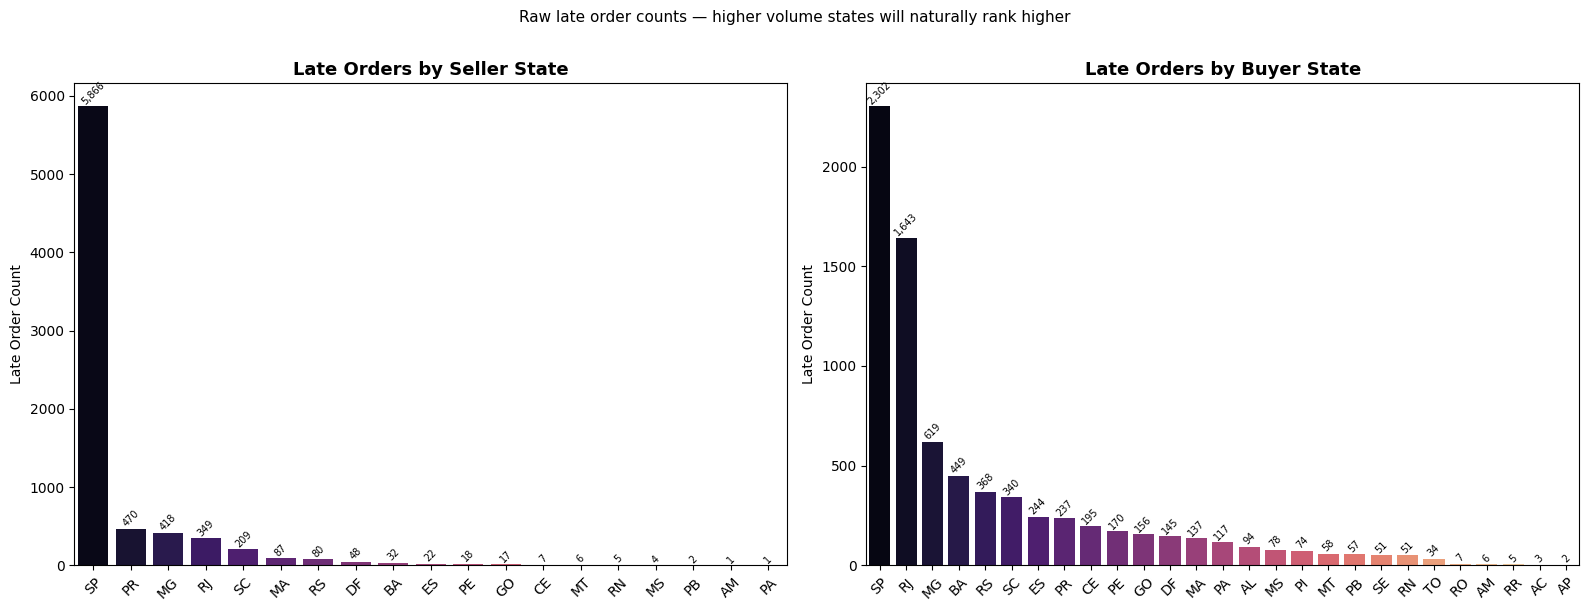

In [10]:
import warnings
warnings.filterwarnings('ignore') 

delayed_orders = df[df['delivery_delay_days'] > 0]
print(f"Total delayed orders: {delayed_orders['order_id'].nunique():,}")

seller_delay_by_state = (
    delayed_orders.groupby('seller_state')['order_id']
    .nunique()
    .sort_values(ascending=False)
    .reset_index()
    .rename(columns={'order_id': 'late_order_count'})
)

buyer_delay_by_state = (
    delayed_orders.groupby('customer_state')['order_id']
    .nunique()
    .sort_values(ascending=False)
    .reset_index()
    .rename(columns={'order_id': 'late_order_count'})
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, data, title, xcol in zip(
    axes,
    [seller_delay_by_state, buyer_delay_by_state],
    ['Late Orders by Seller State', 'Late Orders by Buyer State'],
    ['seller_state', 'customer_state']
):
    sns.barplot(data=data, x=xcol, y='late_order_count', ax=ax, palette='magma')
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('Late Order Count')
    ax.tick_params(axis='x', rotation=45)
    for p in ax.patches:
        if p.get_height() > 0:
            ax.annotate(f'{int(p.get_height()):,}',
                        (p.get_x() + p.get_width() / 2, p.get_height()),
                        ha='center', va='bottom', fontsize=7, rotation=45)

plt.suptitle('Raw late order counts — higher volume states will naturally rank higher',
             fontsize=11, y=1.01)
plt.tight_layout()
plt.show()

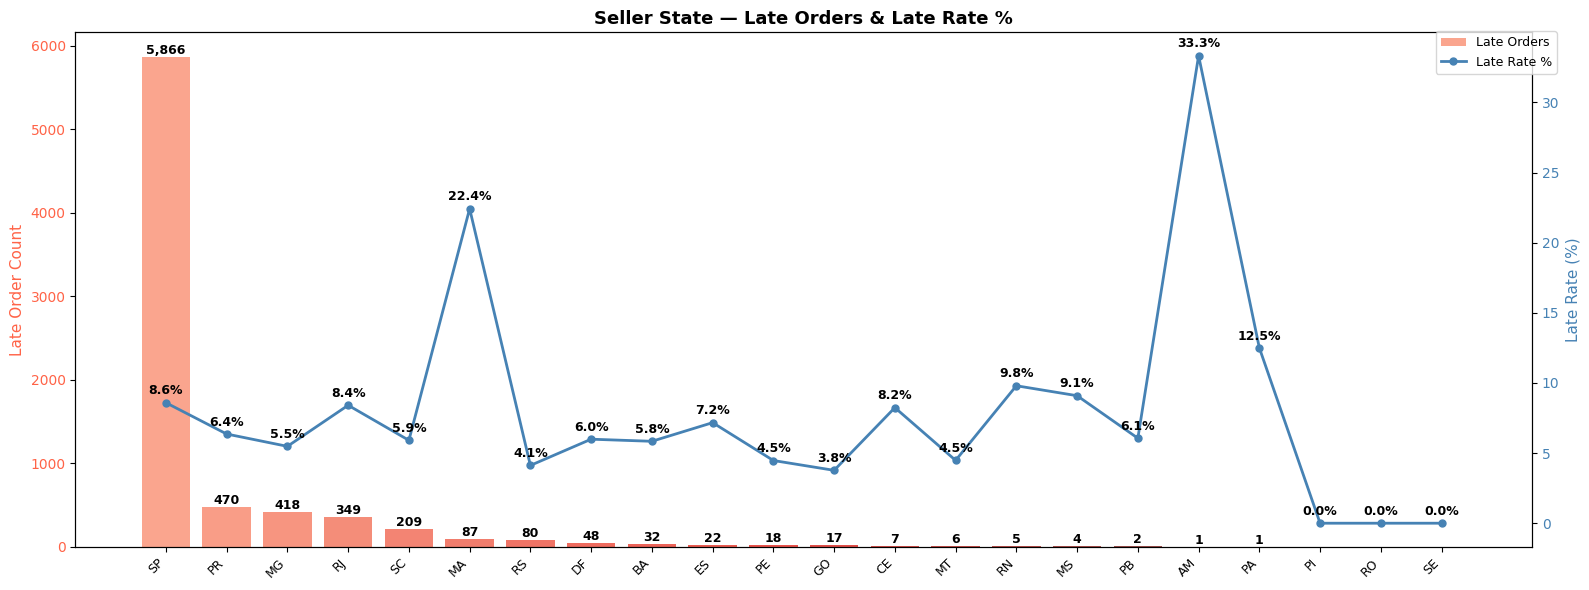

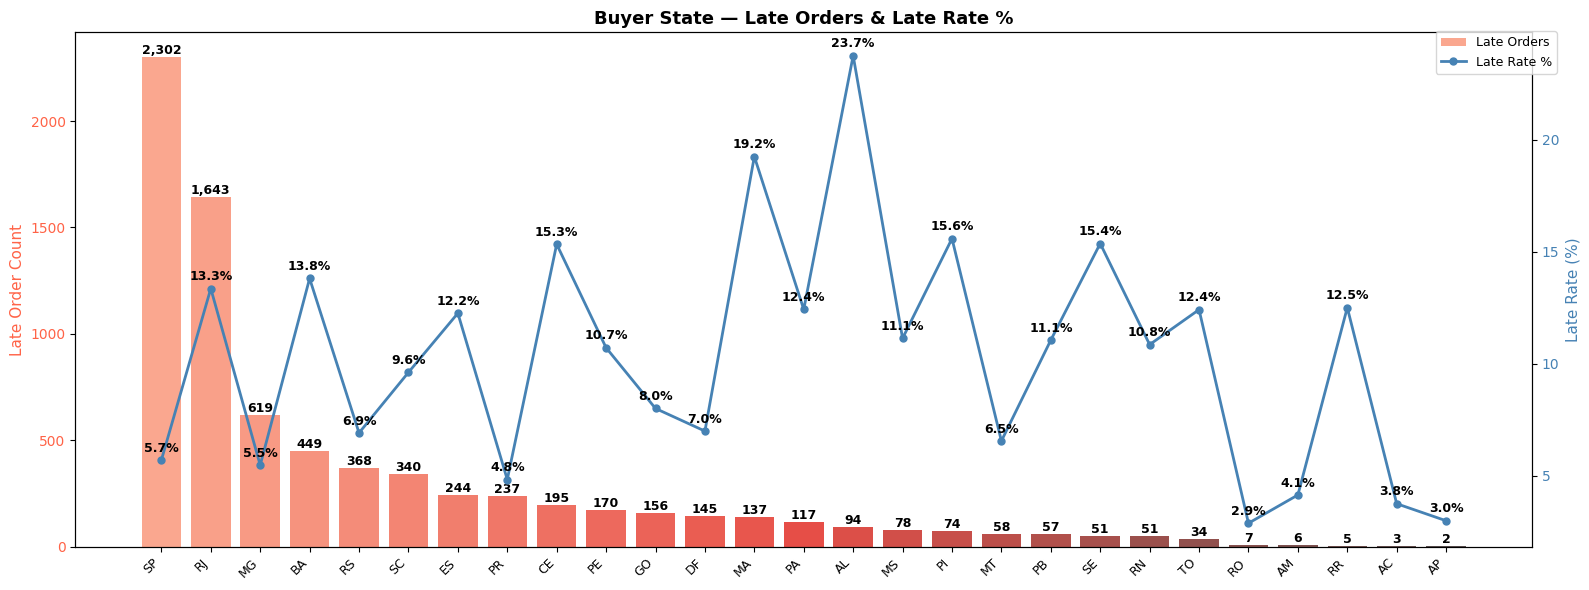

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Build summary DataFrames
seller_summary = (
    df.groupby('seller_state')
    .agg(
        total_orders=('order_id', 'count'),
        late_orders=('is_late', 'sum')
    )
    .reset_index()
)
seller_summary['late_rate_pct'] = (seller_summary['late_orders'] / seller_summary['total_orders'] * 100).round(2)
seller_summary = seller_summary.sort_values('late_orders', ascending=False)

buyer_summary = (
    df.groupby('customer_state')
    .agg(
        total_orders=('order_id', 'count'),
        late_orders=('is_late', 'sum')
    )
    .reset_index()
)
buyer_summary['late_rate_pct'] = (buyer_summary['late_orders'] / buyer_summary['total_orders'] * 100).round(2)
buyer_summary = buyer_summary.sort_values('late_orders', ascending=False)


# Plot function
def plot_state_late(summary, state_col, label):
    fig, ax1 = plt.subplots(figsize=(16, 6))

    x = np.arange(len(summary))

    # Left y-axis: late orders bar
    bars = ax1.bar(x, summary['late_orders'],
                   color=sns.color_palette('Reds_d', len(x)), alpha=0.85, label='Late Orders')
    ax1.set_ylabel('Late Order Count', fontsize=11, color='tomato')
    ax1.tick_params(axis='y', labelcolor='tomato')
    ax1.set_xticks(x)
    ax1.set_xticklabels(summary[state_col], rotation=45, ha='right', fontsize=9)
    ax1.set_xlabel('')
    ax1.yaxis.grid(False)
    ax1.xaxis.grid(False)
    ax1.set_axisbelow(False)

    # Value labels on bars
    for p in bars:
        if p.get_height() > 0:
            ax1.annotate(f'{int(p.get_height()):,}',
                         (p.get_x() + p.get_width() / 2, p.get_height()),
                         ha='center', va='bottom', fontsize=9, color='black', fontweight='bold')

    # Right y-axis: late rate % line
    ax2 = ax1.twinx()
    ax2.plot(x, summary['late_rate_pct'], color='steelblue', marker='o',
             linewidth=2, markersize=5, label='Late Rate %')
    ax2.set_ylabel('Late Rate (%)', fontsize=11, color='steelblue')
    ax2.tick_params(axis='y', labelcolor='steelblue')

    # Value labels on line
    for i, val in enumerate(summary['late_rate_pct']):
        ax2.annotate(f'{val:.1f}%', (i, val),
                     textcoords='offset points', xytext=(0, 6),
                     ha='center', fontsize=9, color='black', fontweight='bold')

    # Legend
    fig.legend(
        handles=[bars, ax2.lines[0]],
        labels=['Late Orders', 'Late Rate %'],
        loc='upper right',
        bbox_to_anchor=(0.98, 0.95),
        fontsize=9,
        frameon=True
    )

    plt.title(f'{label} State — Late Orders & Late Rate %', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()


# Generate plots
plot_state_late(seller_summary, 'seller_state', 'Seller')
plot_state_late(buyer_summary,  'customer_state', 'Buyer')

# Delevery Delay Analysis

In [ ]:
print('\n delivery_delay_days should match manual_check, confirming our calculation is correct.\n')

df[['actual_delivery_days', 'estimated_delivery_days', 'delivery_delay_days']].assign(
    manual_check = df['actual_delivery_days'] - df['estimated_delivery_days']
).head(3)


 delivery_delay_days should match manual_check, confirming our calculation is correct.



,actual_delivery_days,estimated_delivery_days,delivery_delay_days,manual_check
0,8.436574,16.044051,-7.607477,-7.607477
1,13.782037,19.637755,-5.855718,-5.855718
2,9.394213,27.139699,-17.745486,-17.745486


In [ ]:
df[['actual_delivery_days','estimated_delivery_days']].describe()

,actual_delivery_days,estimated_delivery_days
count,96189.000000,96189.000000
mean,12.538347,24.146734
std,9.530783,8.603192
min,0.533414,2.507998
25%,6.756250,18.818148
50%,10.209329,23.714329
75%,15.682731,28.873727
max,209.628611,155.635451


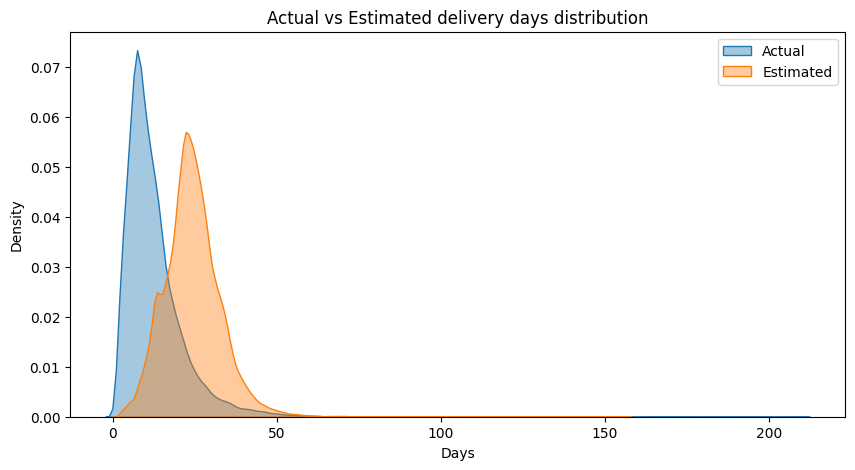

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Overlapping KDE — see how actual vs estimated are distributed
fig, ax = plt.subplots(figsize=(10, 5))
sns.kdeplot(df['actual_delivery_days'], label='Actual', fill=True, alpha=0.4)
sns.kdeplot(df['estimated_delivery_days'], label='Estimated', fill=True, alpha=0.4)
ax.set_xlabel('Days')
ax.set_title('Actual vs Estimated delivery days distribution')
plt.legend()
plt.show()

Total deliveries: 96189
Negative delays (arrived early): 88547, max: -146.51611111111112 days
Zero delay (on time): 0
Positive delays (arrived late): 7642, max: 188.4750925925926 days 


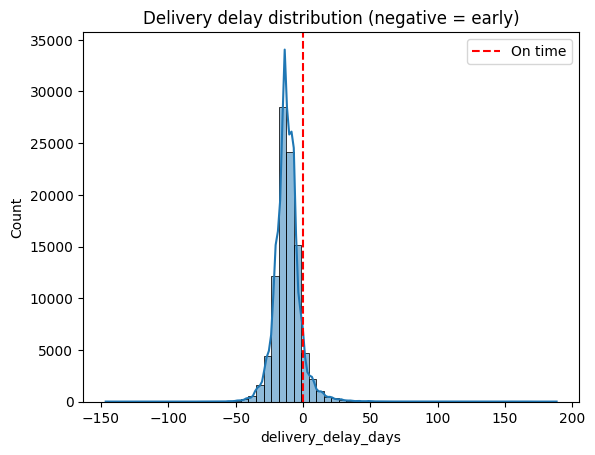

In [ ]:
delay_counts = {
    'negative': (df['delivery_delay_days'] < 0).sum(),
    'zero': (df['delivery_delay_days'] == 0).sum(),
    'positive': (df['delivery_delay_days'] > 0).sum()
}

total_deliveries = len(df)

print(f"Total deliveries: {total_deliveries}")
print(f"Negative delays (arrived early): {delay_counts['negative']}, max: {df['delivery_delay_days'].min()} days")
print(f"Zero delay (on time): {delay_counts['zero']}")
print(f"Positive delays (arrived late): {delay_counts['positive']}, max: {df['delivery_delay_days'].max()} days ")


# delivery_delay_days = actual - estimated (negative = arrived early)
sns.histplot(df['delivery_delay_days'], bins=60, kde=True)
plt.axvline(0, color='red', linestyle='--', label='On time')
plt.title('Delivery delay distribution (negative = early)')
plt.legend()
plt.show()

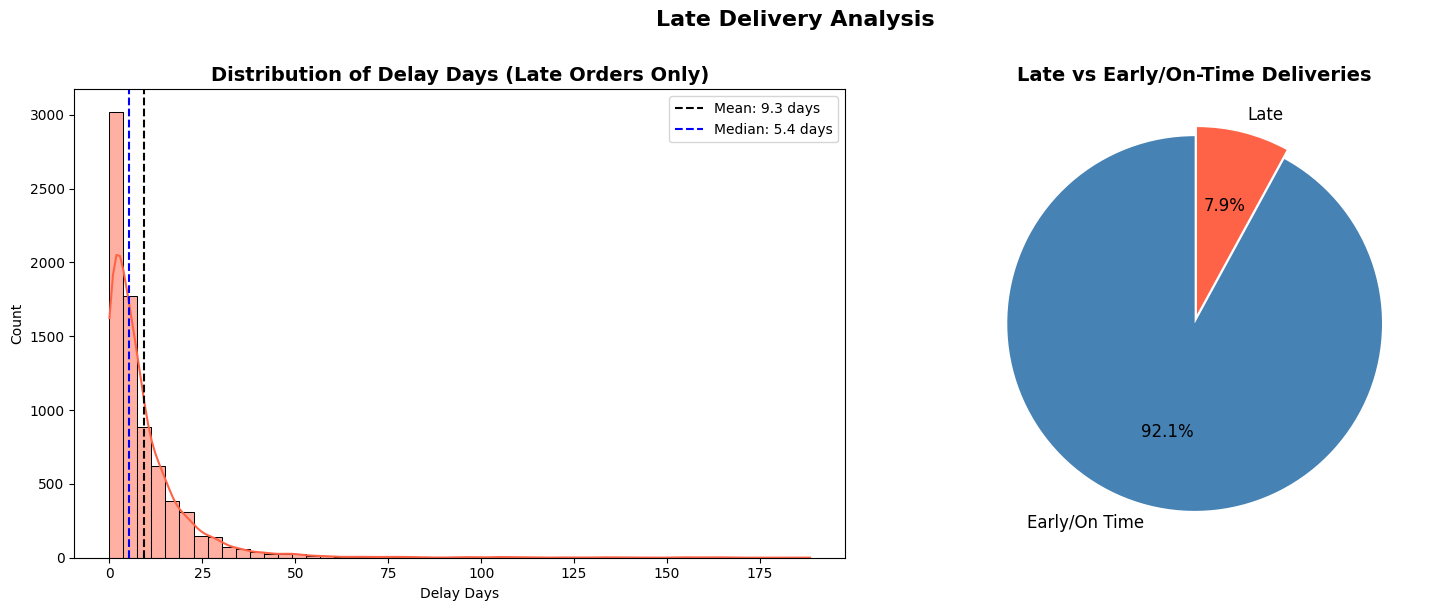


Late orders stats:
  Count     : 7,642 (7.9%)
  Mean delay: 9.3 days
  Max delay : 188.5 days


In [ ]:
late_orders = df[df['delivery_delay_days'] > 0]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Distribution of delay days for late orders
sns.histplot(late_orders['delivery_delay_days'], bins=50, kde=True, color='tomato', ax=axes[0])
axes[0].axvline(late_orders['delivery_delay_days'].mean(), color='black', linestyle='--', label=f"Mean: {late_orders['delivery_delay_days'].mean():.1f} days")
axes[0].axvline(late_orders['delivery_delay_days'].median(), color='blue', linestyle='--', label=f"Median: {late_orders['delivery_delay_days'].median():.1f} days")
axes[0].set_title('Distribution of Delay Days (Late Orders Only)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Delay Days')
axes[0].set_ylabel('Count')
axes[0].legend()

# Late vs On-time pie chart
labels = ['Early/On Time', 'Late']
sizes = [delay_counts['negative'] + delay_counts['zero'], delay_counts['positive']]
colors = ['steelblue', 'tomato']
explode = (0, 0.05)

axes[1].pie(sizes, labels=labels, colors=colors, explode=explode, autopct='%1.1f%%',
            startangle=90, textprops={'fontsize': 12})
axes[1].set_title('Late vs Early/On-Time Deliveries', fontsize=14, fontweight='bold')

plt.suptitle('Late Delivery Analysis', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

print(f"\nLate orders stats:")
print(f"  Count     : {len(late_orders):,} ({len(late_orders)/total_deliveries*100:.1f}%)")
print(f"  Mean delay: {late_orders['delivery_delay_days'].mean():.1f} days")
print(f"  Max delay : {late_orders['delivery_delay_days'].max():.1f} days")

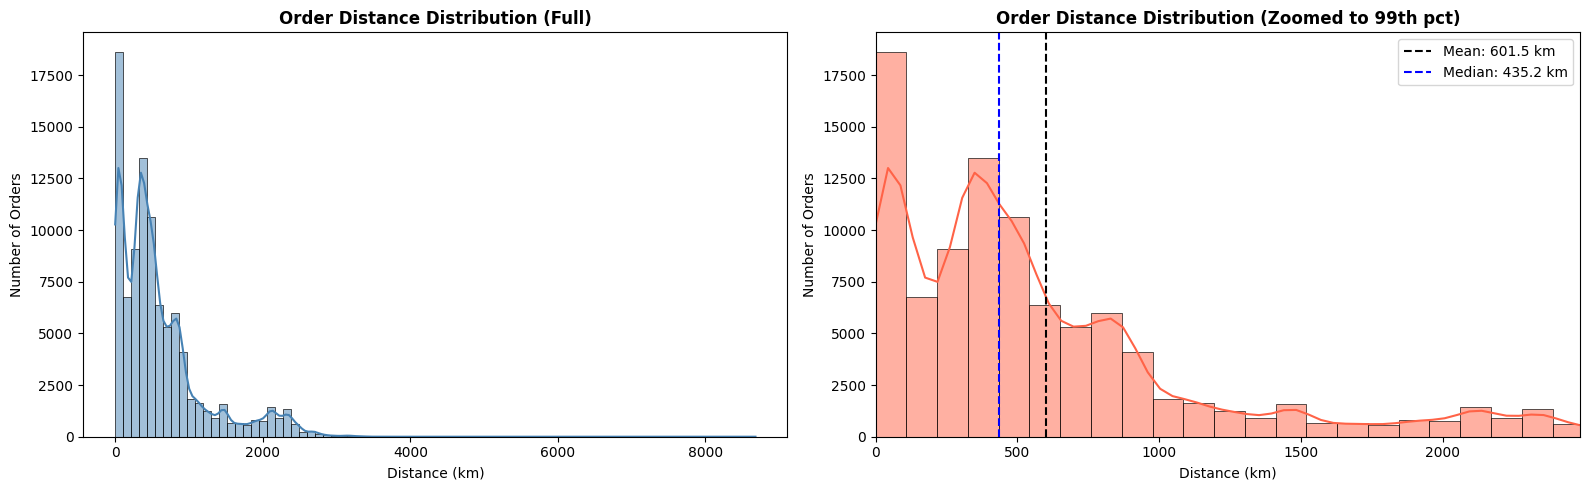

Distance summary -> min: 0.00 km, median: 435.24 km, mean: 601.45 km, max: 8677.91 km
95th percentile: 2094.83 km | 99th percentile: 2483.25 km
99% of all orders had a shipping distance <= 2483.25 km. Shown on the 99th percentile zoom plot on the right side.


In [ ]:
# Distribution of orders with respect to shipping distance
distance = df['distance_km'].dropna()

p95 = distance.quantile(0.95)
p99 = distance.quantile(0.99)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Full distribution
sns.histplot(distance, bins=80, kde=True, color='steelblue', ax=axes[0])
axes[0].set_title('Order Distance Distribution (Full)', fontweight='bold')
axes[0].set_xlabel('Distance (km)')
axes[0].set_ylabel('Number of Orders')

# Zoomed view (up to 99th percentile for readability)
sns.histplot(distance, bins=80, kde=True, color='tomato', ax=axes[1])
axes[1].set_xlim(0, p99)
axes[1].axvline(distance.mean(), color='black', linestyle='--', label=f"Mean: {distance.mean():.1f} km")
axes[1].axvline(distance.median(), color='blue', linestyle='--', label=f"Median: {distance.median():.1f} km")
axes[1].set_title('Order Distance Distribution (Zoomed to 99th pct)', fontweight='bold')
axes[1].set_xlabel('Distance (km)')
axes[1].set_ylabel('Number of Orders')
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Distance summary -> min: {distance.min():.2f} km, median: {distance.median():.2f} km, mean: {distance.mean():.2f} km, max: {distance.max():.2f} km")
print(f"95th percentile: {p95:.2f} km | 99th percentile: {p99:.2f} km")
print(f"99% of all orders had a shipping distance <= {p99:.2f} km. Shown on the 99th percentile zoom plot on the right side.")

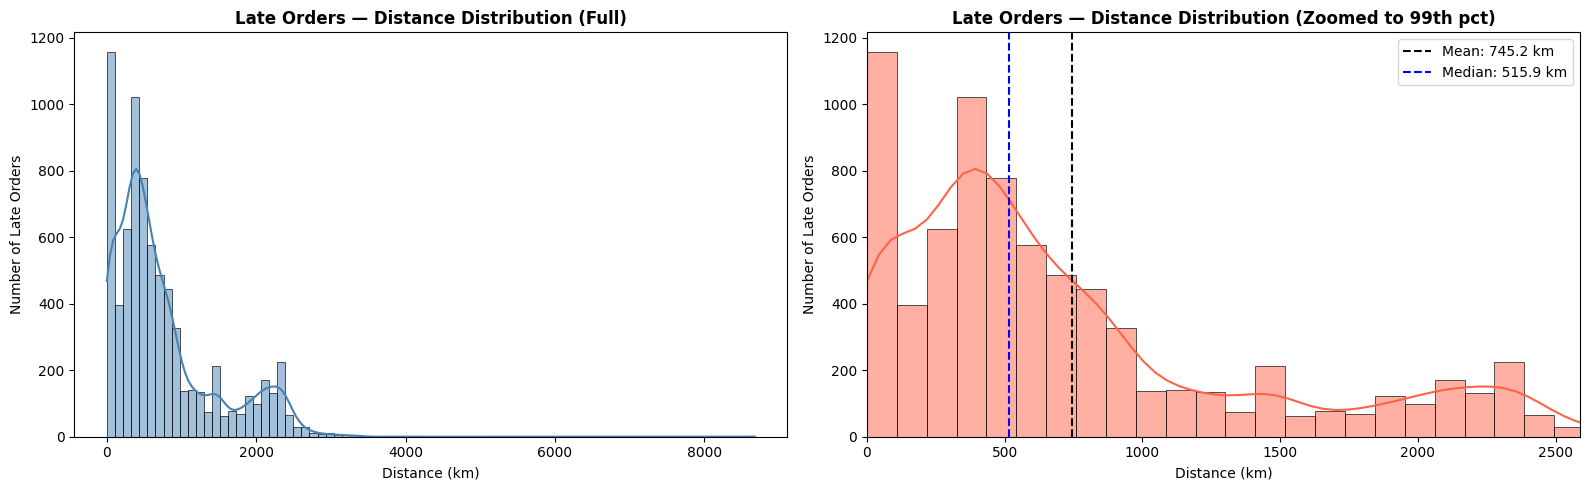

Late orders distance summary:
  Min:    0.00 km
  Median: 515.92 km
  Mean:   745.18 km
  Max:    8677.91 km
  95th percentile: 2289.51 km
  99th percentile: 2588.69 km

99% of late orders had a shipping distance <= 2588.69 km
Total late orders plotted: 7,642


In [ ]:
import warnings
warnings.filterwarnings('ignore')

# Filter late orders only
late_orders = df[df['is_late'] == True]
distance_late = late_orders['distance_km'].dropna()

p95 = distance_late.quantile(0.95)
p99 = distance_late.quantile(0.99)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# ── Full distribution ──────────────────────────────────────────────────────
sns.histplot(distance_late, bins=80, kde=True, color='steelblue', ax=axes[0])
axes[0].set_title('Late Orders — Distance Distribution (Full)', fontweight='bold')
axes[0].set_xlabel('Distance (km)')
axes[0].set_ylabel('Number of Late Orders')

# ── Zoomed to 99th percentile ──────────────────────────────────────────────
sns.histplot(distance_late, bins=80, kde=True, color='tomato', ax=axes[1])
axes[1].set_xlim(0, p99)
axes[1].axvline(distance_late.mean(), color='black', linestyle='--',
                label=f"Mean: {distance_late.mean():.1f} km")
axes[1].axvline(distance_late.median(), color='blue', linestyle='--',
                label=f"Median: {distance_late.median():.1f} km")
axes[1].set_title('Late Orders — Distance Distribution (Zoomed to 99th pct)', fontweight='bold')
axes[1].set_xlabel('Distance (km)')
axes[1].set_ylabel('Number of Late Orders')
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Late orders distance summary:")
print(f"  Min:    {distance_late.min():.2f} km")
print(f"  Median: {distance_late.median():.2f} km")
print(f"  Mean:   {distance_late.mean():.2f} km")
print(f"  Max:    {distance_late.max():.2f} km")
print(f"  95th percentile: {p95:.2f} km")
print(f"  99th percentile: {p99:.2f} km")
print(f"\n99% of late orders had a shipping distance <= {p99:.2f} km")
print(f"Total late orders plotted: {len(distance_late):,}")

# need to write what the below code do aswell.

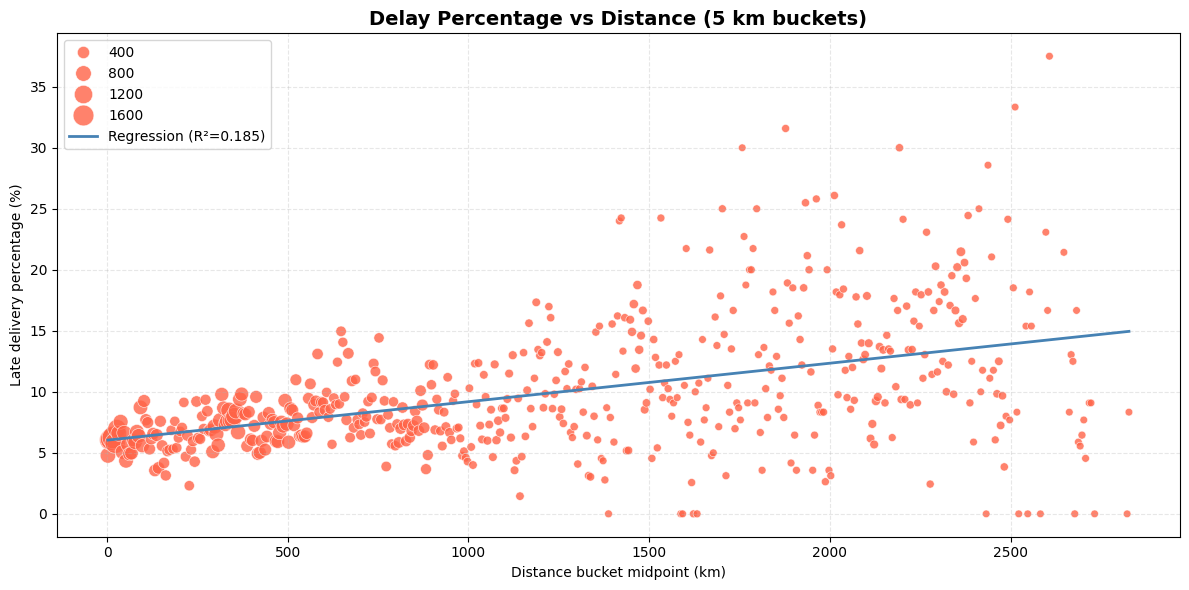

Slope: 0.0032 → each extra km adds 0.0032% delay rate
R²: 0.185 → explains 18.5% of variance in delay %
P-value: 0.0000

Groups orders into 5 km distance buckets and calculates the % of late deliveries per bucket
Filters out buckets with < 10 orders to reduce noise
Plots a bubble chart — x = distance, y = late %, bubble size = order count
Goal: see if longer distances = more delays


In [ ]:
import numpy as np
from scipy import stats

# Delay % by distance bucket (5 km)
bucket_size = 5
min_orders_per_bucket = 10

plot_df = df[['distance_km', 'is_late']].dropna().copy()
max_dist = int(plot_df['distance_km'].max() // bucket_size + 1) * bucket_size
bins = list(range(0, max_dist + bucket_size, bucket_size))

plot_df['distance_bucket'] = pd.cut(
    plot_df['distance_km'],
    bins=bins,
    include_lowest=True,
    right=False
)

delay_by_bucket = (
    plot_df.groupby('distance_bucket')
    .agg(
        orders=('is_late', 'size'),
        delay_pct=('is_late', lambda s: s.mean() * 100)
    )
    .reset_index()
)

delay_by_bucket = delay_by_bucket[delay_by_bucket['orders'] >= min_orders_per_bucket].copy()
delay_by_bucket['distance_mid_km'] = delay_by_bucket['distance_bucket'].apply(lambda x: x.left + bucket_size / 2)

# Regression
x = delay_by_bucket['distance_mid_km']
y = delay_by_bucket['delay_pct']
slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)
x_line = np.linspace(x.min(), x.max(), 200)
y_line = slope * x_line + intercept

# Plot
plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=delay_by_bucket,
    x='distance_mid_km',
    y='delay_pct',
    size='orders',
    sizes=(30, 260),
    color='tomato',
    alpha=0.8
)
plt.plot(x_line, y_line, color='steelblue', linewidth=2, label=f'Regression (R²={r_value**2:.3f})')

plt.title('Delay Percentage vs Distance (5 km buckets)', fontsize=14, fontweight='bold')
plt.xlabel('Distance bucket midpoint (km)')
plt.ylabel('Late delivery percentage (%)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Slope: {slope:.4f} → each extra km adds {slope:.4f}% delay rate")
print(f"R²: {r_value**2:.3f} → explains {r_value**2*100:.1f}% of variance in delay %")
print(f"P-value: {p_value:.4f}")

print("\nGroups orders into 5 km distance buckets and calculates the % of late deliveries per bucket")
print("Filters out buckets with < 10 orders to reduce noise")
print("Plots a bubble chart — x = distance, y = late %, bubble size = order count")
print("Goal: see if longer distances = more delays")

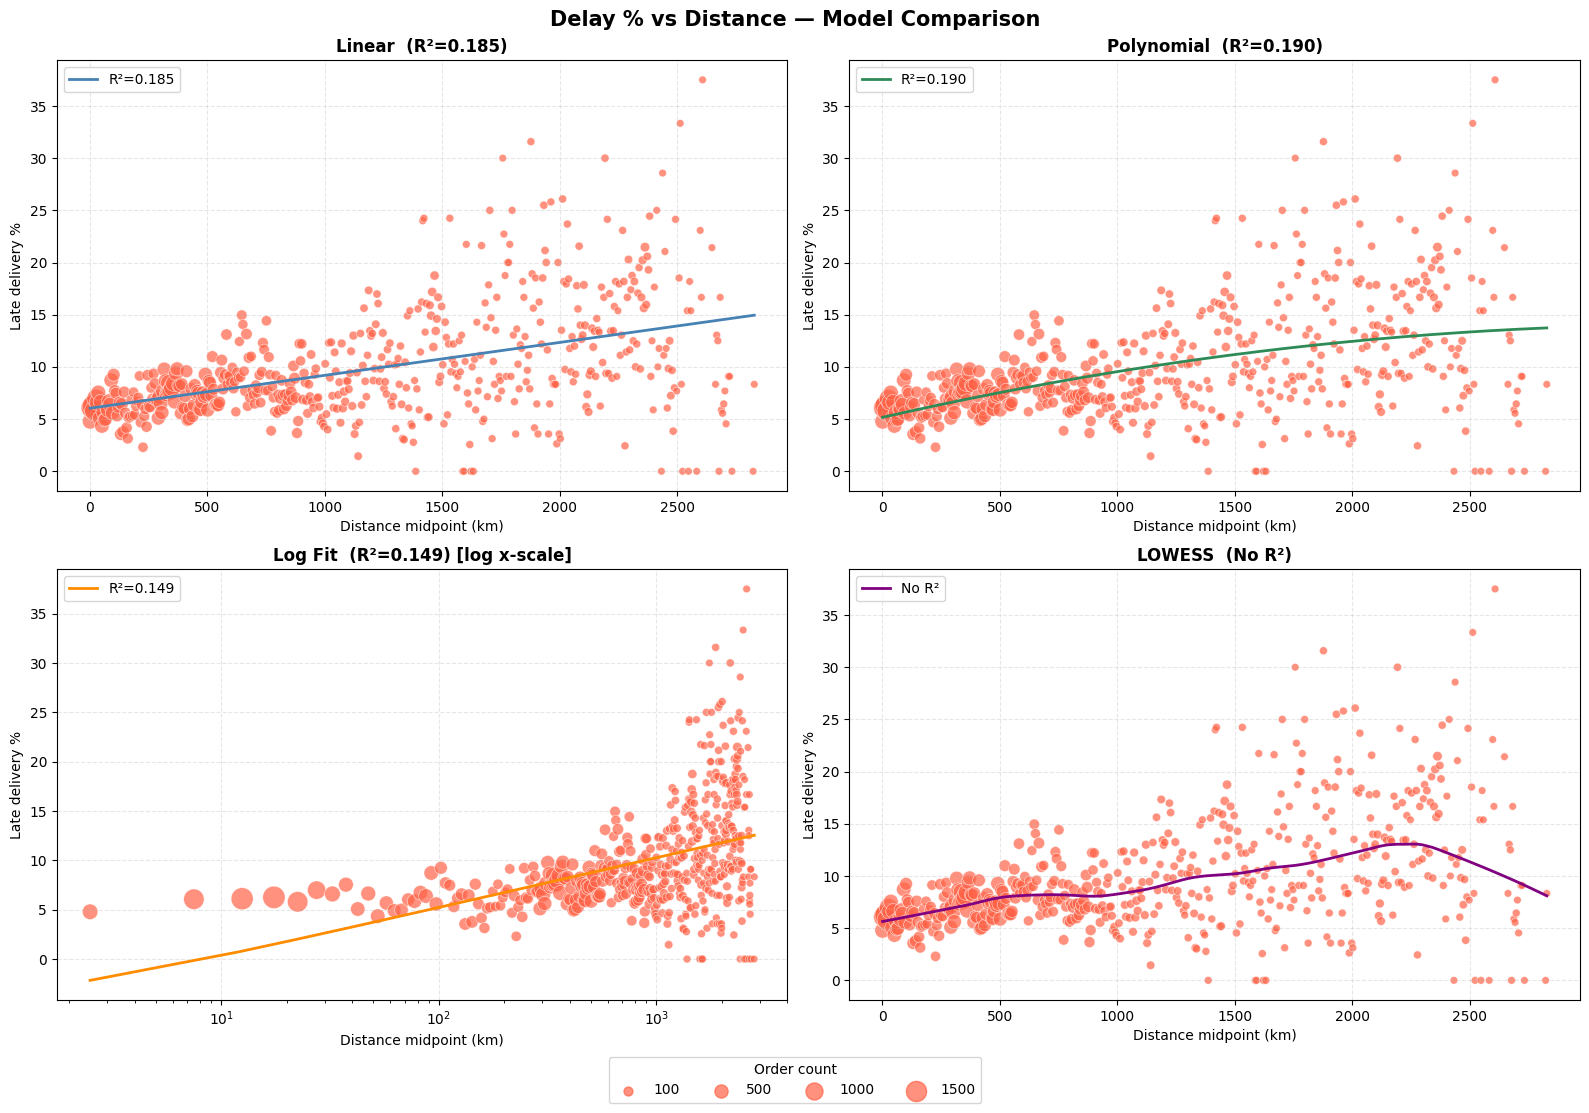

Linear     R²: 0.185
Polynomial R²: 0.190
Log Fit    R²: 0.149
LOWESS: flexible curve, no R² (non-parametric)

All R² values are low (0.15–0.19) — meaning distance alone is a weak predictor of delays


In [ ]:
import pandas as pd
import numpy as np
from scipy import stats
from scipy.optimize import curve_fit
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns

# Delay % by distance bucket (5 km)
bucket_size = 5
min_orders_per_bucket = 10

plot_df = df[['distance_km', 'is_late']].dropna().copy()
max_dist = int(plot_df['distance_km'].max() // bucket_size + 1) * bucket_size
bins = list(range(0, max_dist + bucket_size, bucket_size))

plot_df['distance_bucket'] = pd.cut(
    plot_df['distance_km'],
    bins=bins,
    include_lowest=True,
    right=False
)

delay_by_bucket = (
    plot_df.groupby('distance_bucket')
    .agg(
        orders=('is_late', 'size'),
        delay_pct=('is_late', lambda s: s.mean() * 100)
    )
    .reset_index()
)

delay_by_bucket = delay_by_bucket[delay_by_bucket['orders'] >= min_orders_per_bucket].copy()
delay_by_bucket['distance_mid_km'] = delay_by_bucket['distance_bucket'].apply(lambda x: x.left + bucket_size / 2)

# Fix: explicitly cast to float
x = delay_by_bucket['distance_mid_km'].values.astype(float)
y = delay_by_bucket['delay_pct'].values.astype(float)
x_line = np.linspace(x.min(), x.max(), 300)

# --- 1. Linear ---
slope, intercept, r_linear, p_value, _ = stats.linregress(x, y)
y_linear = slope * x_line + intercept
r2_linear = r_linear**2

# --- 2. Polynomial (degree 2) ---
poly_coeffs = np.polyfit(x, y, 2)
poly_fn = np.poly1d(poly_coeffs)
y_poly = poly_fn(x_line)
y_poly_fit = poly_fn(x)
ss_tot = np.sum((y - y.mean())**2)
ss_res = np.sum((y - y_poly_fit)**2)
r2_poly = 1 - ss_res / ss_tot

# --- 3. Log fit ---
def log_func(x, a, b):
    return a * np.log(x + 1) + b

popt, _ = curve_fit(log_func, x, y)
y_log = log_func(x_line, *popt)
y_log_fit = log_func(x, *popt)
ss_res = np.sum((y - y_log_fit)**2)
r2_log = 1 - ss_res / ss_tot

# --- 4. LOWESS ---
lowess = sm.nonparametric.lowess(y, x, frac=0.3)
lowess_x = lowess[:, 0]
lowess_y = lowess[:, 1]

# --- Plot ---
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle('Delay % vs Distance — Model Comparison', fontsize=15, fontweight='bold')

models = [
    ('Linear',     x_line,   y_linear,  f'R²={r2_linear:.3f}', 'steelblue'),
    ('Polynomial', x_line,   y_poly,    f'R²={r2_poly:.3f}',   'seagreen'),
    ('Log Fit',    x_line,   y_log,     f'R²={r2_log:.3f}',    'darkorange'),
    ('LOWESS',     lowess_x, lowess_y,  'No R²',               'purple'),
]

for i, (ax, (title, xm, ym, r2_label, color)) in enumerate(zip(axes.flatten(), models)):
    sns.scatterplot(
        data=delay_by_bucket,
        x='distance_mid_km',
        y='delay_pct',
        size='orders',
        sizes=(30, 260),
        color='tomato',
        alpha=0.7,
        ax=ax,
        legend=False
    )
    ax.plot(xm, ym, color=color, linewidth=2, label=r2_label)

    # Log scale only for log fit
    if i == 2:
        ax.set_xscale('log')
        ax.set_title(f'{title}  ({r2_label}) [log x-scale]', fontsize=12, fontweight='bold')
    else:
        ax.set_title(f'{title}  ({r2_label})', fontsize=12, fontweight='bold')

    ax.set_xlabel('Distance midpoint (km)')
    ax.set_ylabel('Late delivery %')
    ax.legend(loc='upper left')
    ax.grid(True, linestyle='--', alpha=0.3)

# Bubble size legend at bottom
size_values = [100, 500, 1000, 1500]
legend_handles = [
    plt.scatter([], [], s=np.interp(s, [delay_by_bucket['orders'].min(), delay_by_bucket['orders'].max()], [30, 260]),
                color='tomato', alpha=0.7, label=str(s))
    for s in size_values
]
fig.legend(
    handles=legend_handles,
    labels=[str(s) for s in size_values],
    title='Order count',
    loc='lower center',
    ncol=4,
    bbox_to_anchor=(0.5, -0.02),
    frameon=True,
    fontsize=10
)

plt.tight_layout()
plt.subplots_adjust(bottom=0.08)
plt.show()

print(f"Linear     R²: {r2_linear:.3f}")
print(f"Polynomial R²: {r2_poly:.3f}")
print(f"Log Fit    R²: {r2_log:.3f}")
print("LOWESS: flexible curve, no R² (non-parametric)")
print("\nAll R² values are low (0.15–0.19) — meaning distance alone is a weak predictor of delays")

In [ ]:
df["payment_type"].value_counts()

payment_type
credit_card    73726
boleto         19126
voucher         1856
debit_card      1481
Name: count, dtype: int64

### Payment type distribution and delay rates

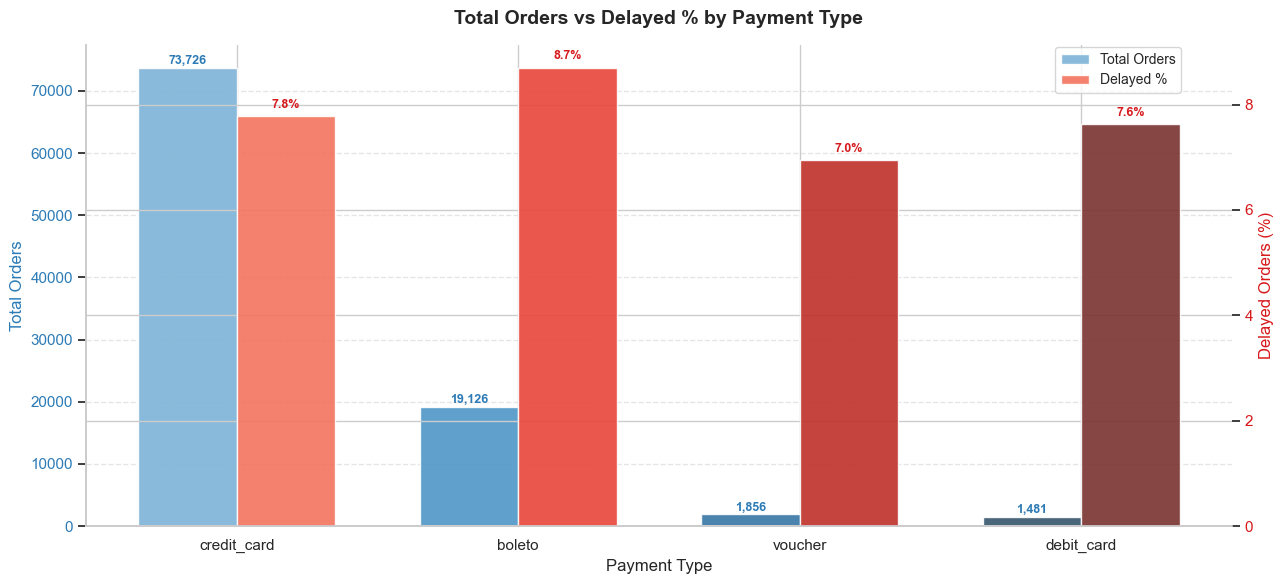

payment_type  total_orders  delayed_pct
 credit_card         73726     7.780159
      boleto         19126     8.700199
     voucher          1856     6.950431
  debit_card          1481     7.629980


In [ ]:
# Summarize by payment type
payment_summary = (
    df.groupby('payment_type')
    .agg(
        total_orders=('is_late', 'size'),
        delayed_pct=('is_late', lambda s: s.mean() * 100)
    )
    .reset_index()
    .sort_values('total_orders', ascending=False)
)

# Melt for seaborn (only total_orders for bar, delayed_pct on twin axis separately)
sns.set_theme(style='whitegrid', palette='muted')

fig, ax1 = plt.subplots(figsize=(13, 6))

x = np.arange(len(payment_summary))
width = 0.35
payment_types = payment_summary['payment_type'].tolist()

# --- Bar 1: Total orders (seaborn-styled via matplotlib) ---
bars1 = ax1.bar(
    x - width/2,
    payment_summary['total_orders'],
    width,
    color=sns.color_palette('Blues_d', len(x)),
    alpha=0.9,
    label='Total Orders'
)
ax1.set_ylabel('Total Orders', fontsize=12, color='#2c7bb6')
ax1.tick_params(axis='y', labelcolor='#2c7bb6')
ax1.set_xticks(x)
ax1.set_xticklabels(payment_types, fontsize=11)
ax1.set_xlabel('Payment Type', fontsize=12)
ax1.yaxis.grid(True, linestyle='--', alpha=0.5)
ax1.set_axisbelow(True)

# --- Bar 2: Delayed % (right axis) ---
ax2 = ax1.twinx()
bars2 = ax2.bar(
    x + width/2,
    payment_summary['delayed_pct'],
    width,
    color=sns.color_palette('Reds_d', len(x)),
    alpha=0.9,
    label='Delayed %'
)
ax2.set_ylabel('Delayed Orders (%)', fontsize=12, color='#d7191c')
ax2.tick_params(axis='y', labelcolor='#d7191c')

# --- Value labels ---
for bar in bars1:
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 150,
        f'{int(bar.get_height()):,}',
        ha='center', va='bottom', fontsize=9, color='#2c7bb6', fontweight='bold'
    )

for bar in bars2:
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.1,
        f'{bar.get_height():.1f}%',
        ha='center', va='bottom', fontsize=9, color='#d7191c', fontweight='bold'
    )

# --- Legend ---
fig.legend(
    handles=[bars1, bars2],
    labels=['Total Orders', 'Delayed %'],
    loc='upper right',
    bbox_to_anchor=(0.92, 0.92),
    fontsize=10,
    frameon=True
)

plt.title('Total Orders vs Delayed % by Payment Type', fontsize=14, fontweight='bold', pad=15)
sns.despine(left=False, bottom=False)
plt.tight_layout()
plt.show()

print(payment_summary.to_string(index=False))

##### Product Category vs No of orders

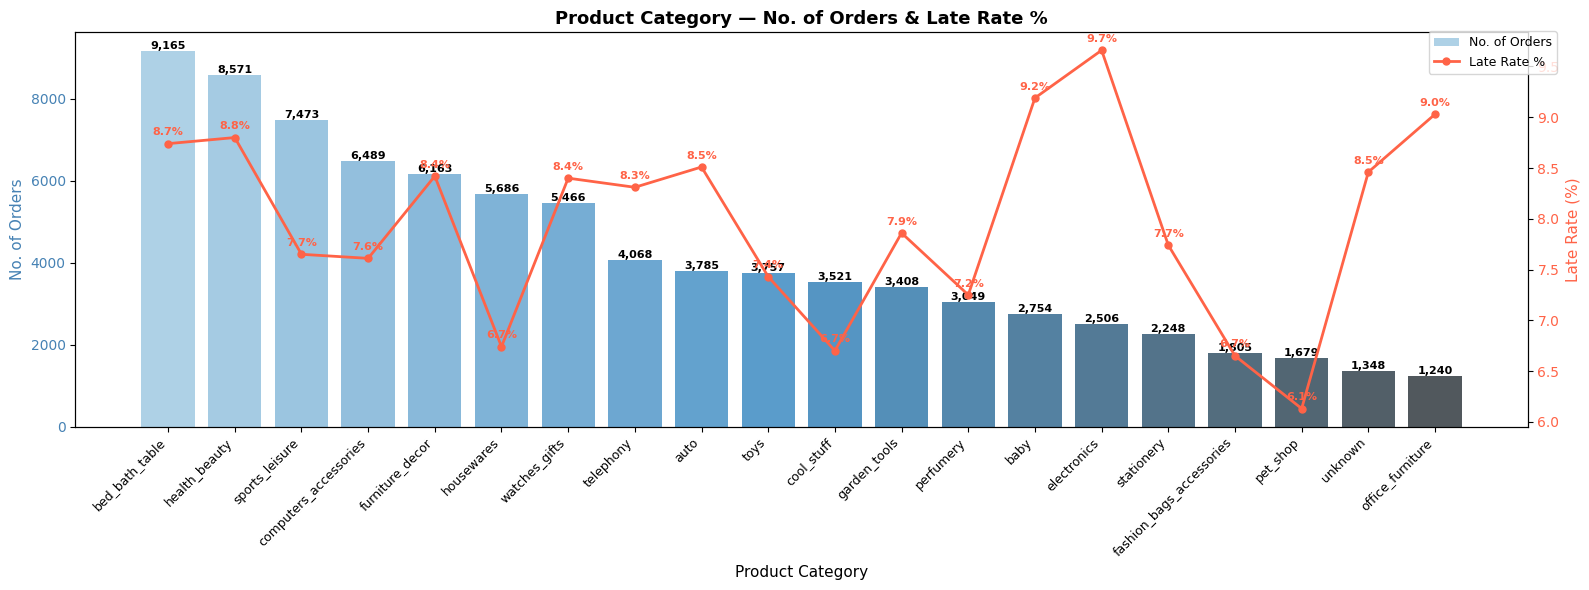

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Step 1: Frequency of orders per primary category
category_counts = (
    df['primary_category']
    .value_counts()
    .reset_index()
)
category_counts.columns = ['primary_category', 'frequency']

# Step 2: Late delivery rate per category
late_rate = (
    df.groupby('primary_category')
    .agg(
        total_orders=('order_id', 'count'),
        late_orders=('is_late', 'sum')
    )
    .reset_index()
)
late_rate['late_rate_pct'] = (late_rate['late_orders'] / late_rate['total_orders'] * 100).round(2)

# Step 3: Merge both on primary_category
category_summary = category_counts.merge(late_rate[['primary_category', 'late_rate_pct']], on='primary_category')

# Step 4: Take top 20 by frequency
top20 = category_summary.head(20)

# Step 5: Plot
fig, ax1 = plt.subplots(figsize=(16, 6))

x = np.arange(len(top20))

# Left y-axis: bar chart (frequency)
bars = ax1.bar(x, top20['frequency'],
               color=sns.color_palette('Blues_d', len(x)), alpha=0.85, label='No. of Orders')
ax1.set_ylabel('No. of Orders', fontsize=11, color='steelblue')
ax1.tick_params(axis='y', labelcolor='steelblue')
ax1.set_xticks(x)
ax1.set_xticklabels(top20['primary_category'], rotation=45, ha='right', fontsize=9)
ax1.set_xlabel('Product Category', fontsize=11)
ax1.yaxis.grid(False)
ax1.xaxis.grid(False)

# Value labels on bars
for p in bars:
    if p.get_height() > 0:
        ax1.annotate(f'{int(p.get_height()):,}',
                     (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha='center', va='bottom', fontsize=8, color='black', fontweight='bold')

# Right y-axis: line chart (late rate %)
ax2 = ax1.twinx()
ax2.plot(x, top20['late_rate_pct'], color='tomato', marker='o',
         linewidth=2, markersize=5, label='Late Rate %')
ax2.set_ylabel('Late Rate (%)', fontsize=11, color='tomato')
ax2.tick_params(axis='y', labelcolor='tomato')

# Value labels on line
for i, val in enumerate(top20['late_rate_pct']):
    ax2.annotate(f'{val:.1f}%', (i, val),
                 textcoords='offset points', xytext=(0, 6),
                 ha='center', fontsize=8, color='tomato', fontweight='bold')

# Legend
fig.legend(
    handles=[bars, ax2.lines[0]],
    labels=['No. of Orders', 'Late Rate %'],
    loc='upper right',
    bbox_to_anchor=(0.98, 0.95),
    fontsize=9,
    frameon=True
)

plt.title('Product Category — No. of Orders & Late Rate %', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()